In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

PROJECT_ROOT = Path.cwd().parent
PROCESSED = PROJECT_ROOT / 'data' / 'processed'
SEED = 42            # same random choices every time you run it
IMG_SIZE = 64

labeled = pd.read_pickle(PROCESSED / 'labeled.pkl')
CLASSES = json.load(open(PROJECT_ROOT / 'data' / 'label_map.json'))

print(labeled.shape)
print(CLASSES)

(172950, 4)
['Center', 'Donut', 'Edge-Loc', 'Edge-Ring', 'Loc', 'Near-full', 'Random', 'Scratch', 'none']


In [2]:
sizes = labeled['waferMap'].apply(lambda m: m.shape)
too_small = sizes.apply(lambda s: min(s) < 10)

print('Dropping', too_small.sum(), 'maps smaller than 10x10')
labeled = labeled[~too_small].reset_index(drop=True)

Dropping 2 maps smaller than 10x10


In [3]:
NONE_CAP = 8000

none_rows  = labeled[labeled['label'] == 'none'].sample(NONE_CAP, random_state=SEED)
other_rows = labeled[labeled['label'] != 'none']

balanced = pd.concat([none_rows, other_rows]).sample(frac=1, random_state=SEED)  # shuffle
balanced = balanced.reset_index(drop=True)

print('Total wafers kept:', len(balanced))
print(balanced['label'].value_counts().reindex(CLASSES))

Total wafers kept: 33519
label
Center       4294
Donut         555
Edge-Loc     5189
Edge-Ring    9680
Loc          3593
Near-full     149
Random        866
Scratch      1193
none         8000
Name: count, dtype: int64


In [4]:
def resize_wafer(wafer_map, size=IMG_SIZE):
    """Resize any wafer map to size x size, keeping values 0/1/2."""
    m = np.asarray(wafer_map, dtype=np.uint8)
    return cv2.resize(m, (size, size), interpolation=cv2.INTER_NEAREST)

X = np.stack([resize_wafer(m) for m in balanced['waferMap']])   # (N, 64, 64)
y = balanced['label_id'].to_numpy(dtype=np.int64)               # (N,)

print('X:', X.shape, X.dtype, 'values:', np.unique(X))
print('y:', y.shape, 'classes:', np.unique(y))

X: (33519, 64, 64) uint8 values: [0 1 2]
y: (33519,) classes: [0 1 2 3 4 5 6 7 8]


In [5]:
from sklearn.model_selection import train_test_split

# First: 70% train, 30% temp
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED)

# Then split temp in half: 15% val, 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

print('Train:', X_train.shape, ' Val:', X_val.shape, ' Test:', X_test.shape)

Train: (23463, 64, 64)  Val: (5028, 64, 64)  Test: (5028, 64, 64)


In [6]:
def counts(arr):
    return pd.Series(arr).value_counts().reindex(range(len(CLASSES)), fill_value=0).values

split_table = pd.DataFrame({
    'train': counts(y_train),
    'val':   counts(y_val),
    'test':  counts(y_test),
}, index=CLASSES)
split_table['total'] = split_table.sum(axis=1)
split_table

,train,val,test,total
Center,3006,644,644,4294
Donut,389,83,83,555
Edge-Loc,3632,778,779,5189
Edge-Ring,6776,1452,1452,9680
Loc,2515,539,539,3593
Near-full,104,23,22,149
Random,606,130,130,866
Scratch,835,179,179,1193
none,5600,1200,1200,8000


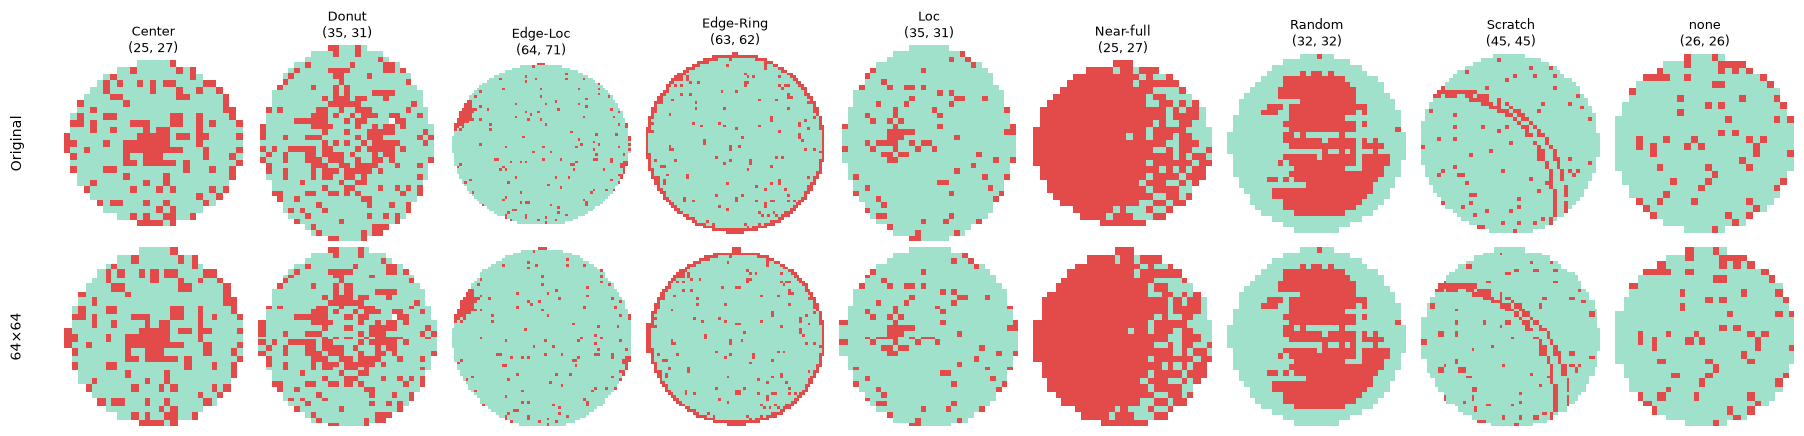

In [8]:
WAFER_CMAP = ListedColormap(['white', '#9FE1CB', '#E24B4A'])

fig, axes = plt.subplots(2, 9, figsize=(18, 4.5))
for col, name in enumerate(CLASSES):
    row = balanced[balanced['label'] == name].iloc[0]
    for r, img in enumerate([row['waferMap'], resize_wafer(row['waferMap'])]):
        axes[r, col].imshow(img, cmap=WAFER_CMAP, vmin=0, vmax=2, interpolation='nearest')
        axes[r, col].axis('off')
    axes[0, col].set_title(f'{name}\n{row["waferMap"].shape}', fontsize=9)

axes[0, 0].text(-0.3, 0.5, 'Original', transform=axes[0, 0].transAxes, rotation=90, va='center')
axes[1, 0].text(-0.3, 0.5, '64×64',    transform=axes[1, 0].transAxes, rotation=90, va='center')
plt.tight_layout()
plt.show()

In [9]:
out_path = PROCESSED / 'wafers_64.npz'
np.savez_compressed(
    out_path,
    X_train=X_train, y_train=y_train,
    X_val=X_val,     y_val=y_val,
    X_test=X_test,   y_test=y_test,
)
print(f'Saved {out_path.name}: {out_path.stat().st_size / 1e6:.1f} MB')

Saved wafers_64.npz: 8.7 MB


In [10]:
data = np.load(out_path)
for key in data.files:
    print(f'{key:8s} {data[key].shape}  {data[key].dtype}')

X_train  (23463, 64, 64)  uint8
y_train  (23463,)  int64
X_val    (5028, 64, 64)  uint8
y_val    (5028,)  int64
X_test   (5028, 64, 64)  uint8
y_test   (5028,)  int64
